# 03 - Train and Compare Models (V2.0)

**What's different from V1:** a subsampling step before training (`training.subsample_training_data`). Your actual `training.gpkg` produces 74,000+ raw pixels; feeding all of them to an RBF-kernel SVM is extremely slow (SVC scales roughly O(n^2)-O(n^3)) and also over-weights whichever class has the largest polygons, since neighboring pixels inside one polygon are highly correlated. Capping per class (`config.MAX_SAMPLES_PER_CLASS`, default 3000) fixes both.

**Before running:** run `02_extract_training_data_v2.ipynb` first.

**Output used by the next notebook:** `models/random_forest.joblib` (or whichever model `config.FINAL_MODEL_FOR_PREDICTION` names)

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path('..') / 'scripts'))

import pandas as pd
import config_v2 as config
import training_v2 as training


## Load training data

In [2]:
df = training.load_training_csv()
print(df.shape)
print(df['class'].value_counts())
df.head()


(1856194, 10)
class
3    768582
2    414532
1    325231
5    223366
4    124483
Name: count, dtype: int64


,B02,B03,B04,B08,B11,B12,NDVI,NDWI,NDBI,class
0,0.2557,0.2263,0.1998,0.1866,0.133106,0.116300,-0.034161,0.096149,-0.167322,1
1,0.2539,0.2251,0.1998,0.1850,0.133631,0.116475,-0.038462,0.097781,-0.161217,1
2,0.2527,0.2250,0.2008,0.1860,0.133194,0.116325,-0.038263,0.094890,-0.165436,1
3,0.2530,0.2259,0.1999,0.1865,0.133069,0.116144,-0.034679,0.095538,-0.167198,1
4,0.2551,0.2236,0.2006,0.1865,0.133256,0.115931,-0.036425,0.090466,-0.166514,1


## Subsample per class (see explanation above), then train/test split

In [3]:
df = training.subsample_training_data(df)
X_train, X_test, y_train, y_test = training.make_train_test_split(df)
print('Train:', X_train.shape, ' Test:', X_test.shape)


Subsampled training data to at most 3000 pixels/class: 1856194 -> 15000 rows
Train: (10500, 9)  Test: (4500, 9)


## Train Random Forest, SVM, Logistic Regression

In [4]:
rf_model = training.train_random_forest(X_train, y_train)
svm_model = training.train_svm(X_train, y_train)
lr_model = training.train_logistic_regression(X_train, y_train)
print('All three models trained.')


All three models trained.


## Evaluate each model


=== Random Forest ===
Overall Accuracy: 0.9687
Precision (weighted): 0.9687
Recall (weighted):    0.9687
F1 (weighted):        0.9687
Cohen's Kappa:        0.9608

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       900
           2       0.94      0.93      0.93       900
           3       0.99      0.99      0.99       900
           4       0.93      0.94      0.93       900
           5       0.99      0.99      0.99       900

    accuracy                           0.97      4500
   macro avg       0.97      0.97      0.97      4500
weighted avg       0.97      0.97      0.97      4500

Saved confusion matrix plot -> D:\2.0\project_v2\outputs\confusion_matrix.png


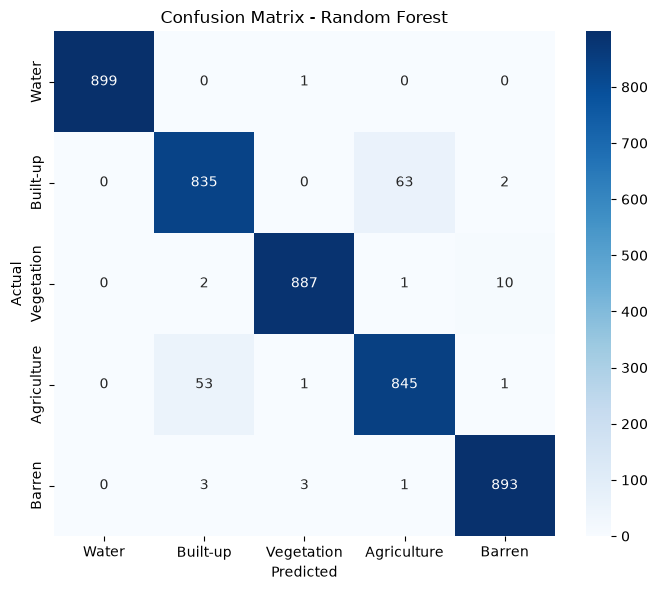

In [5]:
rf_results = training.evaluate_model(rf_model, X_test, y_test, model_name='Random Forest', plot_confusion=True)


In [6]:
svm_results = training.evaluate_model(svm_model, X_test, y_test, model_name='SVM')



=== SVM ===
Overall Accuracy: 0.9518
Precision (weighted): 0.9526
Recall (weighted):    0.9518
F1 (weighted):        0.9519
Cohen's Kappa:        0.9397

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       900
           2       0.92      0.89      0.91       900
           3       0.98      0.97      0.97       900
           4       0.89      0.95      0.92       900
           5       0.97      0.95      0.96       900

    accuracy                           0.95      4500
   macro avg       0.95      0.95      0.95      4500
weighted avg       0.95      0.95      0.95      4500



In [7]:
lr_results = training.evaluate_model(lr_model, X_test, y_test, model_name='Logistic Regression')



=== Logistic Regression ===
Overall Accuracy: 0.8782
Precision (weighted): 0.8790
Recall (weighted):    0.8782
F1 (weighted):        0.8779
Cohen's Kappa:        0.8478

              precision    recall  f1-score   support

           1       0.99      1.00      0.99       900
           2       0.85      0.76      0.81       900
           3       0.96      0.95      0.95       900
           4       0.79      0.85      0.82       900
           5       0.81      0.83      0.82       900

    accuracy                           0.88      4500
   macro avg       0.88      0.88      0.88      4500
weighted avg       0.88      0.88      0.88      4500



## Compare the three models

In [8]:
comparison_df = training.compare_models([rf_results, svm_results, lr_results])
training.save_model_comparison(comparison_df)
comparison_df


Saved model comparison -> D:\2.0\project_v2\outputs\model_comparison.csv


,Model,Accuracy,Precision,Recall,F1,Kappa
0,Random Forest,0.968667,0.968734,0.968667,0.968685,0.960833
1,SVM,0.951778,0.952598,0.951778,0.951912,0.939722
2,Logistic Regression,0.878222,0.878995,0.878222,0.877932,0.847778


## Random Forest feature importance

Saved feature importance plot -> D:\2.0\project_v2\outputs\feature_importance.png


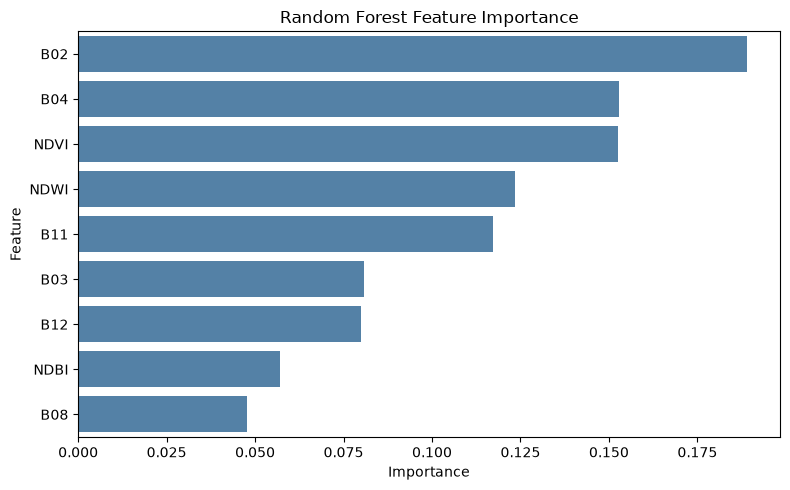

,feature,importance
0,B02,0.188899
1,B04,0.152710
2,NDVI,0.152477
3,NDWI,0.123415
4,B11,0.117103
5,B03,0.080808
6,B12,0.079962
7,NDBI,0.056898
8,B08,0.047727


In [9]:
importance_df = training.get_feature_importance(rf_model)
importance_df.to_csv(config.FEATURE_IMPORTANCE_CSV, index=False)
training.plot_feature_importance(importance_df)
importance_df


## Experiment: bands-only vs indices-only vs all-features

Research question: *Does adding NDVI/NDWI/NDBI improve Sentinel-2 LULC classification compared with raw spectral bands alone?*

In [10]:
experiment_rows = []
for experiment_name, feature_subset in config.FEATURE_SETS.items():
    X_train_sub = X_train[feature_subset]
    X_test_sub = X_test[feature_subset]
    exp_model = training.train_random_forest(X_train_sub, y_train)
    exp_results = training.evaluate_model(
        exp_model, X_test_sub, y_test, model_name=f'RF ({experiment_name})'
    )
    experiment_rows.append(exp_results)

experiment_comparison_df = training.compare_models(experiment_rows)
experiment_comparison_df.to_csv(config.OUTPUTS_DIR / 'feature_set_experiment.csv', index=False)
experiment_comparison_df



=== RF (bands_only) ===
Overall Accuracy: 0.9698
Precision (weighted): 0.9698
Recall (weighted):    0.9698
F1 (weighted):        0.9698
Cohen's Kappa:        0.9622

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       900
           2       0.94      0.93      0.93       900
           3       0.99      0.99      0.99       900
           4       0.93      0.94      0.94       900
           5       0.98      0.99      0.99       900

    accuracy                           0.97      4500
   macro avg       0.97      0.97      0.97      4500
weighted avg       0.97      0.97      0.97      4500


=== RF (indices_only) ===
Overall Accuracy: 0.8569
Precision (weighted): 0.8587
Recall (weighted):    0.8569
F1 (weighted):        0.8572
Cohen's Kappa:        0.8211

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       900
           2       0.80      0.79      0.80       900
           3

,Model,Accuracy,Precision,Recall,F1,Kappa
0,RF (bands_only),0.969778,0.969810,0.969778,0.969776,0.962222
1,RF (all_features),0.968667,0.968734,0.968667,0.968685,0.960833
2,RF (indices_only),0.856889,0.858704,0.856889,0.857188,0.821111


## Save trained models with joblib

In [11]:
training.save_model(rf_model, config.RF_MODEL_PATH)
training.save_model(svm_model, config.SVM_MODEL_PATH)
training.save_model(lr_model, config.LR_MODEL_PATH)


Saved model -> D:\2.0\project_v2\models\random_forest.joblib
Saved model -> D:\2.0\project_v2\models\svm.joblib
Saved model -> D:\2.0\project_v2\models\logistic_regression.joblib


## Done

**Next notebook:** `04_classify_raster_v2.ipynb`